# Chapter 1 — Introduction: Welcome to Deep Learning

> **Book:** *Grokking Deep Learning* (Andrew W. Trask, Manning)
> **Notebook goal:** summarize Chapter 1 and give a small hands-on demo of the central idea of the whole book: *programs that learn from data instead of being written by hand*.

---

## 1. Chapter Summary

Chapter 1 is a motivational and orientation chapter. It does not introduce heavy math or code; instead it answers four questions:

| Question | Short answer |
|---|---|
| **Why should I learn deep learning?** | It is one of the fastest moving, most useful fields in computing; it already powers vision, speech, translation, recommendation and game-playing systems, and it is a skill with high demand. |
| **Why is it "easy" to learn?** | Under the hood, deep learning is built from *very simple* parts (multiplication, addition, a little calculus). Frameworks hide those parts, so people use them without understanding them. The book removes the mystery by building everything from scratch with plain Python + NumPy. |
| **What do I need to know?** | High-school math and basic Python. Everything else (linear algebra, calculus, optimisation) is introduced on the way. |
| **How should I read the book?** | Actively: type the code, change numbers, break things, and run it again. Learning is by doing ("grokking" = understanding deeply and intuitively). |

### Key ideas introduced

1. **Deep learning is a subset of machine learning**, which is a subset of artificial intelligence.
2. **Machine learning = learning from experience.** Instead of explicitly programming rules, we show a system many examples and let it find the rules itself.
3. **Deep learning = machine learning with many-layered neural networks**, whose layers progressively build more abstract representations.
4. **Frameworks (TensorFlow, PyTorch, Keras) are tools, not magic.** Understanding what happens inside is what makes you able to debug, invent and adapt models.
5. **Prerequisites are modest**; the main requirement is *curiosity and persistence*.

### Tools used in the book
- **Python 3** — the language.
- **NumPy** — fast vector / matrix mathematics (the only "framework" used until Chapter 13, where we build our own).
- **Jupyter Notebook** — an interactive environment for running and annotating code (what you are reading now).

---

## 2. Theory Deep-Dive

### 2.1 AI ⊃ Machine Learning ⊃ Deep Learning

```
Artificial Intelligence      – machines doing tasks that normally need human intelligence
 └── Machine Learning        – systems that improve at a task through data / experience
      └── Deep Learning      – ML with multi-layer neural networks (many "deep" layers)
```

* **Artificial intelligence (AI)**: the broad goal of making computers do things that look intelligent.
* **Machine learning (ML)**: a *technique* for reaching that goal. Rather than hand-coding `if/else` rules, we give an algorithm examples and it adjusts internal numbers (*parameters*) until it behaves correctly.
* **Deep learning (DL)**: a family of ML models called *neural networks* that stack many simple processing *layers*. Each layer transforms the data a little bit; stacked together they can model extremely complex relationships (e.g. pixels → edges → shapes → "cat").

### 2.2 Why "learning" instead of "programming"?

Classical programming:

$$\text{rules} + \text{data} \;\longrightarrow\; \text{answers}$$

Machine learning:

$$\text{data} + \text{answers} \;\longrightarrow\; \text{rules}$$

For tasks such as recognising a face or understanding a sentence, nobody can write the rules by hand — there are too many exceptions. ML lets the computer *discover* the rules.

### 2.3 Why deep learning is accessible

A neural network is, at its core, nothing but

* **multiplication and addition** (weighted sums),
* a simple **non-linearity** (e.g. "if negative, set to zero"),
* a **learning rule** based on a derivative (how much did the error change if I nudge this number?).

Everything else is repetition at scale. The rest of the book re-derives each part from first principles.

### 2.4 Why build from scratch if frameworks exist?

| With a framework only | With from-scratch understanding |
|---|---|
| You can train standard models | You can *debug* them when they fail |
| You copy architectures | You can *invent* new ones |
| Hyper-parameters feel like superstition | You know what each one does |

### 2.5 How to learn effectively (book's advice)
* Learn **by doing** — reproduce the code (this assignment!).
* Treat each chapter as a **building block**; later chapters depend on earlier ones.
* **Experiment**: change one number at a time and observe the result.

---

## 3. Hands-on Demo — "Learning" a rule from data

The book's Chapter 1 has no code, so here is a minimal demonstration of the idea above.

**Task:** convert temperature from Celsius to Fahrenheit.

* *Classical programming*: we know the rule `F = 1.8·C + 32` and write it by hand.
* *Machine learning*: we **don't** tell the program the rule. We only show examples `(C, F)` and let it find two numbers — a **weight** `w` and a **bias** `b` — such that `F ≈ w·C + b`. It will do this with the *predict → compare → learn* loop that the rest of the book formalises.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os, sys

os.makedirs("folder-picture", exist_ok=True)
print("Python :", sys.version.split()[0])
print("NumPy  :", np.__version__)

# --- Classical programming: the rule is written by a human -------------------
def celsius_to_fahrenheit_rule(c):
    return 1.8 * c + 32

# --- Machine learning: the rule is discovered from examples ------------------
rng = np.random.default_rng(0)
C = rng.uniform(-40, 40, size=50)          # inputs  (data)
F = celsius_to_fahrenheit_rule(C)          # answers (labels)

w, b = 0.0, 0.0                            # start knowing nothing
alpha = 0.0005                             # learning rate (how big each nudge is)
history = []

for step in range(300):
    pred  = w * C + b                      # 1) PREDICT
    error = pred - F                       # 2) COMPARE
    mse   = np.mean(error ** 2)
    history.append(mse)
    w -= alpha * np.mean(error * C) * 2    # 3) LEARN: move against the gradient
    b -= alpha * np.mean(error) * 2 * 20   #    (bias given a bigger step: its input is the constant 1)

print(f"learned  w = {w:.3f}, b = {b:.3f}   (true rule: w = 1.8, b = 32)")
print("Prediction for 100 °C:", round(w * 100 + b, 2), "°F   (rule says 212)")

Python : 3.12.3
NumPy  : 2.4.4
learned  w = 1.800, b = 31.922   (true rule: w = 1.8, b = 32)
Prediction for 100 °C: 211.95 °F   (rule says 212)


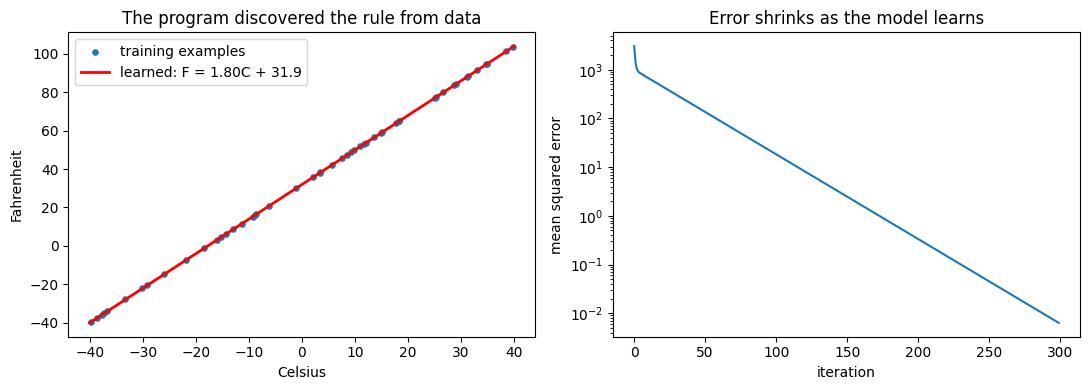

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].scatter(C, F, s=14, label="training examples")
xs = np.linspace(-40, 40, 100)
ax[0].plot(xs, w * xs + b, "r", lw=2, label=f"learned: F = {w:.2f}C + {b:.1f}")
ax[0].set_xlabel("Celsius"); ax[0].set_ylabel("Fahrenheit")
ax[0].set_title("The program discovered the rule from data"); ax[0].legend()

ax[1].plot(history)
ax[1].set_yscale("log")
ax[1].set_xlabel("iteration"); ax[1].set_ylabel("mean squared error")
ax[1].set_title("Error shrinks as the model learns")

plt.tight_layout()
plt.savefig("folder-picture/ch01_learning_from_data.png", dpi=120, bbox_inches="tight")
plt.show()

## 4. Key Takeaways

* Deep learning ⊂ machine learning ⊂ AI; ML replaces hand-written rules with **rules learned from examples**.
* The building blocks are **simple** (weighted sums, non-linearities, derivatives); power comes from stacking and repetition.
* The book teaches by **building from scratch** with NumPy so that frameworks stop being black boxes.
* The demo above already contains the heart of every later chapter: **predict → compare → learn**.

➡️ **Next:** Chapter 2 formalises these ideas — parametric vs non-parametric models, supervised vs unsupervised learning.